<a href="https://colab.research.google.com/github/Reddy0402/SAP_AI_Assignment_01/blob/main/GenAI_Lab_VLM_Object_Identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GenAI Lab — What's in the Image?
**Object identification with small vision-language models** (LFM2.5-VL-1.6B vs InternVL3.5-1B)

Run on Colab with a **T4 GPU** (Runtime → Change runtime type → T4). Run top to bottom.
After the first cell (`pip install`), **restart the runtime once**, then run from Cell 2 onward.

Pipeline: Part A ground truth → Part B run both models (same images, same prompt, greedy) → Part C parse & score → Part D error analysis → results table → write-up.

In [ ]:
# CELL 1 — install. Restart the runtime after this finishes (Runtime > Restart session), then continue from CELL 2.
!pip install -q -U transformers datasets accelerate pillow matplotlib pandas
import transformers; print("transformers", transformers.__version__)   # LFM2.5-VL needs >= 5.1

transformers 5.20.2


In [5]:
# CELL 2 — imports, config, GPU check
import json, time, gc, os, random
from collections import Counter
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import transformers
from transformers import pipeline
from datasets import load_dataset

assert torch.cuda.is_available(), "Switch the Colab runtime to a T4 GPU."
print("transformers", transformers.__version__, "| GPU:", torch.cuda.get_device_name(0))

N_IMAGES        = 100        # first 100 images of the COCO val split
SMALL_AREA_FRAC = 0.01       # boxes covering < 1% of the image are "small"
MAX_NEW_TOKENS  = 256        # enough for a JSON array of class names
RERUN           = False      # True = ignore cached raw outputs and re-run the models

MODELS = {                   # display name -> HF repo (order = table column order)
    "LFM2.5-VL-1.6B": "LiquidAI/LFM2.5-VL-1.6B",
    "InternVL3.5-1B": "OpenGVLab/InternVL3_5-1B-HF",
}
random.seed(0); np.random.seed(0); torch.manual_seed(0)

transformers 5.20.1 | GPU: Tesla T4


## Part A — Ground truth
Stream only the **val** split (never download train, ~19 GB), take 100 images, and build:
1. the set of unique class names per image,
2. the same set after dropping boxes covering < 1% of the image area,
3. the 80 class names, read from the dataset's category feature (not typed by hand).

In [6]:
# CELL 3 — load the data (streaming) and inspect the fields BEFORE writing logic
ds = load_dataset("detection-datasets/coco", split="val", streaming=True)
samples = list(ds.take(N_IMAGES))
print(len(samples), "samples; keys:", samples[0].keys())
s0 = samples[0]
print({k: (type(v).__name__) for k, v in s0.items()})
print("objects keys:", s0["objects"].keys())
print("example objects:", {k: v[:3] for k, v in s0["objects"].items()})
print("image size:", s0["image"].size, "| width/height fields:", s0.get("width"), s0.get("height"))

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

100 samples; keys: dict_keys(['image_id', 'image', 'width', 'height', 'objects'])
{'image_id': 'int', 'image': 'JpegImageFile', 'width': 'int', 'height': 'int', 'objects': 'dict'}
objects keys: dict_keys(['bbox_id', 'category', 'bbox', 'area'])
example objects: {'bbox_id': [26547, 34646, 35802], 'category': [58, 62, 62], 'bbox': [[236.98, 142.51, 261.68, 212.01], [7.03, 167.76, 156.35, 262.63], [557.21, 209.19, 638.5600000000001, 287.92]], 'area': [531.8071000000001, 13244.657700000002, 5833.117949999999]}
image size: (640, 426) | width/height fields: 640 426


In [7]:
# CELL 4 — the 80 class names from the dataset's category feature
def get_class_names(ds):
    feats = ds.features
    if feats is None:
        return None
    cat = feats["objects"]["category"]
    cat = getattr(cat, "feature", cat)      # works for Sequence(...) and List(...) wrappers
    return list(cat.names)

CLASSES = get_class_names(ds)
if CLASSES is None:
    # Streaming sometimes drops feature metadata: read it from the builder instead (still from the dataset, not typed).
    from datasets import load_dataset_builder
    b = load_dataset_builder("detection-datasets/coco")
    cat = b.info.features["objects"]["category"]
    CLASSES = list(getattr(cat, "feature", cat).names)

CLASS_SET = set(CLASSES)
print(len(CLASSES), "classes:", CLASSES[:10], "...")
assert len(CLASSES) == 80, f"expected 80 classes, got {len(CLASSES)}"

80 classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light'] ...


In [8]:
# CELL 5 — build ground truth (all objects, and large objects only)
def cat_name(c):
    return CLASSES[c] if isinstance(c, (int, np.integer)) else c   # ints -> names (strings pass through)

# Detect the bbox format from the data instead of assuming it (xyxy vs xywh).
def looks_like_xyxy(samples):
    for s in samples:
        W, H = s["image"].size
        for x1, y1, x2, y2 in s["objects"]["bbox"]:
            if not (x2 > x1 and y2 > y1 and x2 <= W + 1 and y2 <= H + 1):
                return False
    return True

BBOX_XYXY = looks_like_xyxy(samples)
print("bbox format:", "xyxy [x_min,y_min,x_max,y_max]" if BBOX_XYXY else "xywh [x,y,w,h]")

def box_area(b):
    x1, y1, a, b2 = b
    return (a - x1) * (b2 - y1) if BBOX_XYXY else a * b2

GT_ALL, GT_LARGE = [], []
for s in samples:
    W, H = s["image"].size
    names  = [cat_name(c) for c in s["objects"]["category"]]
    fracs  = [box_area(b) / (W * H) for b in s["objects"]["bbox"]]
    GT_ALL.append(set(names))
    GT_LARGE.append({n for n, f in zip(names, fracs) if f >= SMALL_AREA_FRAC})

print("avg unique classes / image  (all):", np.mean([len(g) for g in GT_ALL]).round(2),
      "| (large only):", np.mean([len(g) for g in GT_LARGE]).round(2))
print("example 0:", sorted(GT_ALL[0]), "| large:", sorted(GT_LARGE[0]))
assert all(g <= CLASS_SET for g in GT_ALL), "ground truth has a class outside the 80"

bbox format: xyxy [x_min,y_min,x_max,y_max]
avg unique classes / image  (all): 2.88 | (large only): 2.16
example 0: ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase'] | large: ['chair', 'dining table', 'person', 'tv', 'vase']


## Part B — Prompt and run
The **exact same prompt**, same 100 images, same greedy decoding (`do_sample=False`), fp16, for both models.
For each model we record: raw output per image, latency per image (GPU-synchronised), and peak GPU memory
(`reset_peak_memory_stats()` before the run, `max_memory_allocated()` after). One untimed warm-up call is made first so
CUDA/kernel start-up cost doesn't pollute latency. Raw outputs are cached to disk so a crash doesn't lose them.

In [9]:
# CELL 6 — prompt (identical for both models; do not tune per model)
CLASS_LIST = ", ".join(CLASSES)
PROMPT = (
    "List every object you can see in this image that belongs to the allowed classes below.\n"
    'Return ONLY a JSON array of class names, each name at most once. Example: ["person", "dog"]\n'
    f"Allowed classes: {CLASS_LIST}"
)
print(PROMPT[:330], "...")

List every object you can see in this image that belongs to the allowed classes below.
Return ONLY a JSON array of class names, each name at most once. Example: ["person", "dog"]
Allowed classes: person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign, parking meter, bench, bir ...


In [10]:
# CELL 7 — helpers to load a pipeline, call it, and pull the text out of the result
def load_pipe(repo):
    kw = dict(task="image-text-to-text", model=repo, device_map="cuda")
    try:
        return pipeline(**kw, dtype=torch.float16)          # transformers >= 5
    except TypeError:
        return pipeline(**kw, torch_dtype=torch.float16)    # older versions

def extract_text(out):
    g = out[0]["generated_text"]
    if isinstance(g, str):
        return g
    last = g[-1]["content"]                                   # chat-format output: last assistant turn
    if isinstance(last, list):
        last = "".join(p.get("text", "") for p in last if isinstance(p, dict))
    return last

def generate(pipe, img, prompt):
    msgs = [{"role": "user", "content": [{"type": "image", "image": img},
                                         {"type": "text",  "text": prompt}]}]
    out = pipe(text=msgs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, return_full_text=False)
    return extract_text(out)

def rgb(img):                      # a few COCO images are grayscale
    return img.convert("RGB")

In [11]:
# CELL 8 — run both models (takes roughly 5-15 min on a T4 the first time, mostly downloads)
RESULTS = {}
for name, repo in MODELS.items():
    cache = f"/content/raw_{name}.json"
    if os.path.exists(cache) and not RERUN:
        RESULTS[name] = json.load(open(cache)); print(f"[{name}] loaded cached results"); continue

    print(f"\n=== {name} ({repo}) ===")
    pipe = load_pipe(repo)
    _ = generate(pipe, rgb(samples[0]["image"]), PROMPT)       # untimed warm-up
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()

    raws, lats = [], []
    for i, s in enumerate(samples):
        img = rgb(s["image"])
        torch.cuda.synchronize(); t0 = time.perf_counter()
        raws.append(generate(pipe, img, PROMPT))
        torch.cuda.synchronize(); lats.append(time.perf_counter() - t0)
        if (i + 1) % 20 == 0: print(f"  {i+1}/{N_IMAGES}  avg latency so far {np.mean(lats):.2f}s")

    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    RESULTS[name] = {"raw": raws, "latency": lats, "peak_gb": peak_gb}
    json.dump(RESULTS[name], open(cache, "w"))
    print(f"[{name}] peak GPU memory: {peak_gb:.2f} GB | sample raw output: {raws[0][:150]!r}")

    del pipe; gc.collect(); torch.cuda.empty_cache()              # free the GPU before the next model


=== LFM2.5-VL-1.6B (LiquidAI/LFM2.5-VL-1.6B) ===


config.json:   0%|          | 0.00/2.38k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.19GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/589 [00:00<?, ?it/s]

...

  60/100  avg latency so far 5.12s


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

  80/100  avg latency so far 5.48s


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

  100/100  avg latency so far 5.36s
[InternVL3.5-1B] peak GPU memory: 4.34 GB | sample raw output: '["person", "tv", "refrigerator", "chair", "dining table", "vase", "potted plant", "clock", "chair", "table", "vase", "refrigerator", "chair", "chair",'


## Part C — Parse and score
An output is **invalid** if it is not valid JSON, is not a JSON array of strings, or contains a name outside the 80 classes.
Invalid outputs are **counted, not repaired** (no stripping of ```json fences, no fuzzy matching). In the P/R/F1 maths an
invalid output contributes an **empty prediction** (`INVALID_AS_EMPTY = True`) — it earns no true positives and its
ground-truth labels count as missed, so being invalid costs recall rather than being silently excluded.

In [12]:
# CELL 9 — strict parsing + per-image scoring
INVALID_AS_EMPTY = True

def parse_output(raw):
    """Return (set_of_names | None, reason | None). Strict: no repair of the model's output."""
    try:
        obj = json.loads(raw.strip())
    except Exception:
        return None, "bad_json"
    if not isinstance(obj, list) or not all(isinstance(x, str) for x in obj):
        return None, "wrong_type"
    if any(x not in CLASS_SET for x in obj):
        return None, "out_of_vocab"
    return set(obj), None            # duplicates collapse to a set ("each name at most once")

def score_model(name):
    R = RESULTS[name]; rows = []
    for i, raw in enumerate(R["raw"]):
        pred, reason = parse_output(raw)
        valid = pred is not None
        p = pred if valid else set()                      # INVALID_AS_EMPTY
        gt, gtl = GT_ALL[i], GT_LARGE[i]
        rows.append(dict(
            idx=i, valid=valid, reason=reason, pred=p, gt=gt, gt_large=gtl, raw=raw,
            tp=len(p & gt), n_pred=len(p), n_gt=len(gt),
            tp_large=len(p & gtl), n_gt_large=len(gtl),
            fp=sorted(p - gt), fn=sorted(gt - p),
            halluc=len(p - gt) > 0, latency=R["latency"][i]))
    return pd.DataFrame(rows)

def sdiv(a, b): return a / b if b else 0.0

def summarize(name, df):
    tp, n_pred, n_gt = df.tp.sum(), df.n_pred.sum(), df.n_gt.sum()
    tpl, n_gt_l = df.tp_large.sum(), df.n_gt_large.sum()
    P, R, RL = sdiv(tp, n_pred), sdiv(tp, n_gt), sdiv(tpl, n_gt_l)
    return {"precision": P, "recall_all": R, "recall_large": RL, "f1": sdiv(2*P*R, P+R),
            "hallucination": float(df.halluc.mean()),
            "valid_json": float(df.valid.mean()),
            "latency": float(df.latency.mean()),
            "peak_gb": RESULTS[name]["peak_gb"], "n_scored": len(df)}

PER     = {n: score_model(n) for n in MODELS if n in RESULTS}
METRICS = {n: summarize(n, PER[n]) for n in PER}

print("INVALID_AS_EMPTY =", INVALID_AS_EMPTY)
for n, df in PER.items():
    reasons = Counter(df.reason.dropna())
    fenced = sum(r.strip().startswith("```") for r in df.raw)
    print(f"\n[{n}] invalid outputs: {int((~df.valid).sum())} / {len(df)}")
    print("   breakdown:", {k: reasons.get(k, 0) for k in ["bad_json", "wrong_type", "out_of_vocab"]})
    print(f"   (diagnostic) outputs wrapped in ``` fences: {fenced}  <- counted invalid, not repaired")

INVALID_AS_EMPTY = True

[LFM2.5-VL-1.6B] invalid outputs: 81 / 100
   breakdown: {'bad_json': 30, 'wrong_type': 0, 'out_of_vocab': 51}
   (diagnostic) outputs wrapped in ``` fences: 0  <- counted invalid, not repaired

[InternVL3.5-1B] invalid outputs: 58 / 100
   breakdown: {'bad_json': 22, 'wrong_type': 0, 'out_of_vocab': 36}
   (diagnostic) outputs wrapped in ``` fences: 0  <- counted invalid, not repaired


In [13]:
# CELL 10 — sanity checks so you can trust the numbers
for n, df in PER.items():
    assert len(df) == N_IMAGES
    assert (df.tp <= df.n_pred).all() and (df.tp <= df.n_gt).all()
    assert (df.tp_large <= df.n_gt_large).all()
    print(f"[{n}] OK | total GT labels {df.n_gt.sum()} (large {df.n_gt_large.sum()}), predicted labels {df.n_pred.sum()}, TP {df.tp.sum()}")
print("\nFirst 3 raw outputs per model:")
for n in PER:
    for i in range(3): print(f"  [{n}] img {i}: {RESULTS[n]['raw'][i][:160]!r}")

[LFM2.5-VL-1.6B] OK | total GT labels 288 (large 216), predicted labels 79, TP 39
[InternVL3.5-1B] OK | total GT labels 288 (large 216), predicted labels 95, TP 76

First 3 raw outputs per model:
  [LFM2.5-VL-1.6B] img 0: '["person", "tv", "potted plant", "dining table", "chair", "fireplace", "clock", "vase", "potted plant", "dining table", "chair", "fireplace", "potted plant", "d'
  [LFM2.5-VL-1.6B] img 1: '["bear"]'
  [LFM2.5-VL-1.6B] img 2: '["bed", "dresser", "mirror", "bookshelf", "window", "plant", "basket", "chair", "potted plant", "dresser", "books", "bookshelf", "window", "plant", "basket", "c'
  [InternVL3.5-1B] img 0: '["person", "tv", "refrigerator", "chair", "dining table", "vase", "potted plant", "clock", "chair", "table", "vase", "refrigerator", "chair", "chair", "chair", '
  [InternVL3.5-1B] img 1: '["bear"]'
  [InternVL3.5-1B] img 2: '["bed", "potted plant", "book", "mirror", "dresser", "chair", "basket", "bookshelf", "pillow", "lamp", "couch", "window", "clothes", "va

## Results table

In [14]:
# CELL 11 — results table (put this at the top of your write-up)
def f3(x, d=3): return f"{x:.{d}f}"
names = [n for n in MODELS if n in METRICS]
rows = [
    ("Precision",                  lambda m: f3(m["precision"])),
    ("Recall (all / large only)",  lambda m: f'{f3(m["recall_all"])} / {f3(m["recall_large"])}'),
    ("F1",                         lambda m: f3(m["f1"])),
    ("Hallucination rate",         lambda m: f'{m["hallucination"]*100:.1f}%'),
    ("Valid-JSON rate",            lambda m: f'{m["valid_json"]*100:.1f}%'),
    ("Latency (s/image)",          lambda m: f3(m["latency"], 2)),
    ("Peak GPU memory (GB)",       lambda m: f3(m["peak_gb"], 2)),
]
results_df = pd.DataFrame({n: [fn(METRICS[n]) for _, fn in rows] for n in names}, index=[r[0] for r in rows])
results_df.index.name = "Metric"
display(results_df)
results_df.to_csv("/content/results_table.csv")
print(results_df.to_markdown())          # paste this into your write-up

,LFM2.5-VL-1.6B,InternVL3.5-1B
Metric,,
Precision,0.494,0.800
Recall (all / large only),0.135 / 0.162,0.264 / 0.310
F1,0.213,0.397
Hallucination rate,9.0%,13.0%
Valid-JSON rate,19.0%,42.0%
Latency (s/image),2.11,5.36
Peak GPU memory (GB),3.09,4.34


| Metric                    | LFM2.5-VL-1.6B   | InternVL3.5-1B   |
|:--------------------------|:-----------------|:-----------------|
| Precision                 | 0.494            | 0.800            |
| Recall (all / large only) | 0.135 / 0.162    | 0.264 / 0.310    |
| F1                        | 0.213            | 0.397            |
| Hallucination rate        | 9.0%             | 13.0%            |
| Valid-JSON rate           | 19.0%            | 42.0%            |
| Latency (s/image)         | 2.11             | 5.36             |
| Peak GPU memory (GB)      | 3.09             | 4.34             |


## Part D — Error analysis
Three failure cases per model, chosen automatically so the choice isn't cherry-picked:
**(1)** the image with the most hallucinated labels, **(2)** the image with the most missed *large* objects, **(3)** an invalid output
(or, if there is none, the next-worst hallucination). Each shows the image, the model's raw output and the ground truth.
Then **you** write one line on *why* — that part is the point of the exercise, so it is left blank for you.

In [2]:
import os
from google.colab import files

# Ensure 'samples' is loaded from the COCO dataset if missing in the environment
if 'samples' not in globals():
    print("'samples' not found in memory. Streaming dataset to load them...")
    from datasets import load_dataset
    ds = load_dataset("detection-datasets/coco", split="val", streaming=True)
    samples = list(ds.take(100))

# Create a directory to store the images
output_dir = "/content/coco_images"
os.makedirs(output_dir, exist_ok=True)

# Save each image using its image_id as the filename
for s in samples:
    img = s["image"]
    img_id = s["image_id"]
    img.save(f"{output_dir}/{img_id}.jpg")

print(f"Saved {len(samples)} images to {output_dir}/")

# Zip the folder for easy downloading
!zip -q -r coco_images.zip /content/coco_images
print("Created coco_images.zip")

# Trigger browser download of the zip file
files.download("coco_images.zip")

'samples' not found in memory. Streaming dataset to load them...


README.md:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

dataset_infos.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

Saved 100 images to /content/coco_images/
Created coco_images.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# CELL 12.5 — Print ONLY the missing third failure case for InternVL3.5-1B without plotting images to avoid truncation
i = FAILS["InternVL3.5-1B"][2]
r = PER["InternVL3.5-1B"][PER["InternVL3.5-1B"].idx == i].iloc[0]
print(f"=== InternVL3.5-1B: Missing Case (Image {i}) ===")
print(f"Model output : {r.raw[:300]!r}")
print(f"Valid        : {r.valid}" + (f"  (reason: {r.reason})" if not r.valid else ""))
print(f"Ground truth : {sorted(r['gt'])}")
print(f"Ground truth (large only): {sorted(r['gt_large'])}")
print(f"Hallucinated : {r.fp}   | Missed: {r.fn}")

=== InternVL3.5-1B: Missing Case (Image 0) ===
Model output : '["person", "tv", "refrigerator", "chair", "dining table", "vase", "potted plant", "clock", "chair", "table", "vase", "refrigerator", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chai'
Valid        : False  (reason: bad_json)
Ground truth : ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
Ground truth (large only): ['chair', 'dining table', 'person', 'tv', 'vase']
Hallucinated : []   | Missed: ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']


### Error-analysis notes
LFM2.5-VL-1.6B

Image 93 (laptop desk scene): listed 24 classes that are not present. It appears to dump much of the class list instead of describing the image.

Image 28 (dining table): fell into a repetition loop and never closed the array, so all 6 correct objects were lost as invalid.

Image 0 (living room): looped on potted plant / dining table / chair / fireplace, and "fireplace" is outside the 80 classes.


InternVL3.5-1B

Image 84 (street, motorcycle): added bench, stop sign, cell phone, potted plant and backpack, and missed bicycle and chair.

Image 28 (dining table): used out-of-vocabulary names (tissue, bread, wine) and omitted person, so the output was invalid.

Image 0 (living room): repeated "chair" until the token limit, giving invalid JSON.





########## LFM2.5-VL-1.6B: failure cases [93, 28, 0] ##########


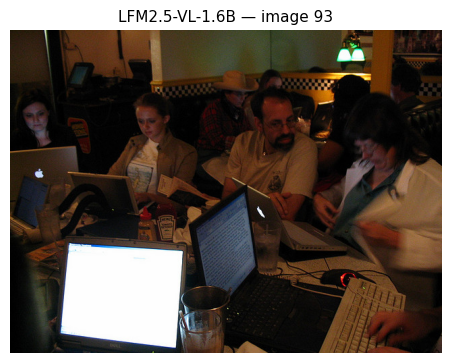

Model output : '["person", "laptop", "mouse", "keyboard", "tv", "dining table", "bottle", "cup", "remote", "backpack", "handbag", "tie", "suitcase", "chair", "couch", "potted plant", "dining table", "tv", "laptop", "mouse", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator", "book", "c'
Valid        : True
Ground truth : ['cup', 'keyboard', 'laptop', 'mouse', 'person']
Ground truth (large only): ['cup', 'keyboard', 'laptop', 'person']
Hallucinated : ['backpack', 'book', 'bottle', 'cell phone', 'chair', 'clock', 'couch', 'dining table', 'hair drier', 'handbag', 'microwave', 'oven', 'potted plant', 'refrigerator', 'remote', 'scissors', 'sink', 'suitcase', 'teddy bear', 'tie', 'toaster', 'toothbrush', 'tv', 'vase']   | Missed: []
------------------------------------------------------------------------------------------


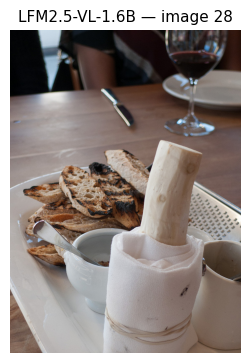

Model output : '["person", "dining table", "knife", "wine glass", "bowl", "spoon", "sandwich", "carrot", "hot dog", "pizza", "cake", "chair", "dining table", "knife", "wine glass", "bowl", "spoon", "sandwich", "carrot", "hot dog", "pizza", "cake", "chair", "dining table", "knife", "wine glass", "bowl", "spoon", "sa'
Valid        : False  (reason: bad_json)
Ground truth : ['cup', 'dining table', 'knife', 'person', 'spoon', 'wine glass']
Ground truth (large only): ['cup', 'dining table', 'knife', 'person', 'spoon', 'wine glass']
Hallucinated : []   | Missed: ['cup', 'dining table', 'knife', 'person', 'spoon', 'wine glass']
------------------------------------------------------------------------------------------


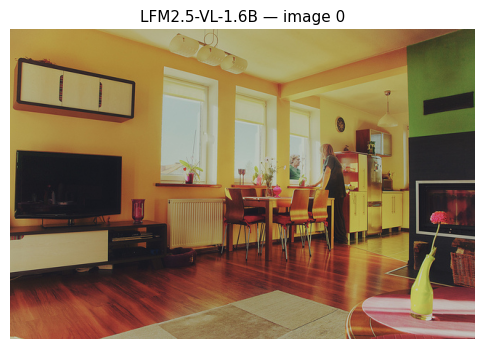

Model output : '["person", "tv", "potted plant", "dining table", "chair", "fireplace", "clock", "vase", "potted plant", "dining table", "chair", "fireplace", "potted plant", "dining table", "chair", "fireplace", "potted plant", "dining table", "chair", "fireplace", "potted plant", "dining table", "chair", "fireplac'
Valid        : False  (reason: bad_json)
Ground truth : ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
Ground truth (large only): ['chair', 'dining table', 'person', 'tv', 'vase']
Hallucinated : []   | Missed: ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
------------------------------------------------------------------------------------------

########## InternVL3.5-1B: failure cases [84, 28, 0] ##########


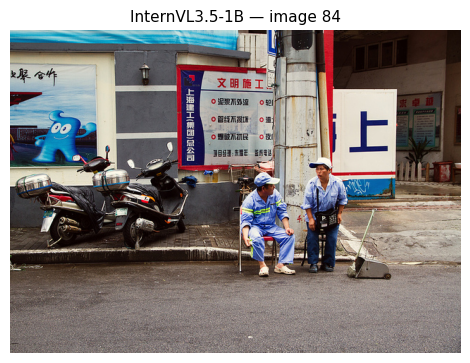

Model output : '["person", "motorcycle", "bench", "cell phone", "stop sign", "potted plant", "backpack"]'
Valid        : True
Ground truth : ['bicycle', 'chair', 'motorcycle', 'person']
Ground truth (large only): ['bicycle', 'chair', 'motorcycle', 'person']
Hallucinated : ['backpack', 'bench', 'cell phone', 'potted plant', 'stop sign']   | Missed: ['bicycle', 'chair']
------------------------------------------------------------------------------------------


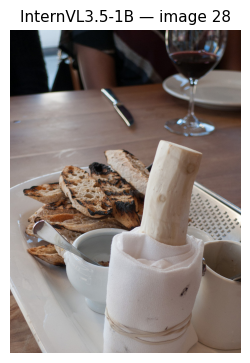

Model output : '["wine glass", "knife", "spoon", "bowl", "tissue", "dining table", "bread", "wine", "cup"]'
Valid        : False  (reason: out_of_vocab)
Ground truth : ['cup', 'dining table', 'knife', 'person', 'spoon', 'wine glass']
Ground truth (large only): ['cup', 'dining table', 'knife', 'person', 'spoon', 'wine glass']
Hallucinated : []   | Missed: ['cup', 'dining table', 'knife', 'person', 'spoon', 'wine glass']
------------------------------------------------------------------------------------------


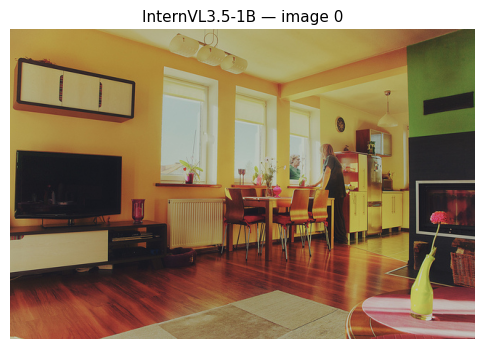

Model output : '["person", "tv", "refrigerator", "chair", "dining table", "vase", "potted plant", "clock", "chair", "table", "vase", "refrigerator", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chair", "chai'
Valid        : False  (reason: bad_json)
Ground truth : ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
Ground truth (large only): ['chair', 'dining table', 'person', 'tv', 'vase']
Hallucinated : []   | Missed: ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
------------------------------------------------------------------------------------------


In [15]:
# CELL 12 — pick and show the failure cases
def pick_failures(df, k=3):
    chosen = []
    def add(i):
        if i is not None and i not in chosen: chosen.append(int(i))
    d = df.assign(n_fp=df.fp.map(len), n_miss_large=df.n_gt_large - df.tp_large)
    add(d.sort_values(["n_fp", "n_gt"], ascending=False).idx.iloc[0])                     # worst hallucination
    add(d.sort_values(["n_miss_large", "n_gt_large"], ascending=False).idx.iloc[0])       # most missed large objects
    inv = d[~d.valid]
    if len(inv): add(inv.idx.iloc[0])                                                      # an invalid output
    for i in d.sort_values("n_fp", ascending=False).idx:                                   # top up to k
        if len(chosen) >= k: break
        add(i)
    return chosen[:k]

def show_case(name, df, i):
    r = df[df.idx == i].iloc[0]
    fig, ax = plt.subplots(figsize=(6, 4.2)); ax.imshow(samples[i]["image"]); ax.axis("off")
    ax.set_title(f"{name} — image {i}", fontsize=11); plt.show()
    print(f"Model output : {r.raw[:300]!r}")
    print(f"Valid        : {r.valid}" + (f"  (reason: {r.reason})" if not r.valid else ""))
    print(f"Ground truth : {sorted(r['gt'])}")
    print(f"Ground truth (large only): {sorted(r['gt_large'])}")
    print(f"Hallucinated : {r.fp}   | Missed: {r.fn}\n" + "-" * 90)

FAILS = {n: pick_failures(PER[n]) for n in PER}
for n in PER:
    print(f"\n########## {n}: failure cases {FAILS[n]} ##########")
    for i in FAILS[n]: show_case(n, PER[n], i)

## Write-up — supporting numbers
The cell below prints the numbers you need to answer the four questions. The answers and your observations are yours to write.

In [17]:
# CELL 13 — numbers to support your answers (no conclusions are drawn for you)
if len(names) == 2:
    a, b = names
    A, B = METRICS[a], METRICS[b]
    print(f"Q1  F1: {a} {A['f1']:.3f} vs {b} {B['f1']:.3f} (delta {A['f1']-B['f1']:+.3f}) | "
          f"halluc: {A['hallucination']:.1%} vs {B['hallucination']:.1%} | "
          f"latency: {A['latency']:.2f}s vs {B['latency']:.2f}s | memory: {A['peak_gb']:.2f} vs {B['peak_gb']:.2f} GB")
    print(f"\nQ3  Recall all -> large-only:")
    for n in names:
        m = METRICS[n]; print(f"    {n}: {m['recall_all']:.3f} -> {m['recall_large']:.3f}  (change {m['recall_large']-m['recall_all']:+.3f})")

    print("\nQ2  Most frequently hallucinated classes per model:")
    for n in names:
        c = Counter(x for fp in PER[n].fp for x in fp).most_common(8)
        print(f"    {n}: {c}")
    print("\n    Hallucination vs scene complexity (images grouped by number of GT classes):")
    for n in names:
        df = PER[n].assign(bucket=pd.cut(PER[n].n_gt, [0, 1, 3, 100], labels=["1 class", "2-3 classes", "4+ classes"]))
        print(f"    {n}:", df.groupby("bucket", observed=True).halluc.mean().round(3).to_dict())

    print("\nQ4  Throughput (images/sec):", {n: round(1 / METRICS[n]["latency"], 2) for n in names})

Q1  F1: LFM2.5-VL-1.6B 0.213 vs InternVL3.5-1B 0.397 (delta -0.184) | halluc: 9.0% vs 13.0% | latency: 2.11s vs 5.36s | memory: 3.09 vs 4.34 GB

Q3  Recall all -> large-only:
    LFM2.5-VL-1.6B: 0.135 -> 0.162  (change +0.027)
    InternVL3.5-1B: 0.264 -> 0.310  (change +0.046)

Q2  Most frequently hallucinated classes per model:
    LFM2.5-VL-1.6B: [('book', 3), ('laptop', 2), ('remote', 2), ('tv', 2), ('clock', 2), ('scissors', 2), ('toaster', 2), ('toothbrush', 2)]
    InternVL3.5-1B: [('bench', 3), ('laptop', 2), ('potted plant', 2), ('bear', 1), ('cup', 1), ('toothbrush', 1), ('apple', 1), ('car', 1)]

    Hallucination vs scene complexity (images grouped by number of GT classes):
    LFM2.5-VL-1.6B: {'1 class': 0.182, '2-3 classes': 0.078, '4+ classes': 0.08}
    InternVL3.5-1B: {'1 class': 0.182, '2-3 classes': 0.141, '4+ classes': 0.08}

Q4  Throughput (images/sec): {'LFM2.5-VL-1.6B': 0.47, 'InternVL3.5-1B': 0.19}


## Write-up — answers

**Results table:** paste the table from Cell 11 at the top of your write-up.

**1. Does LFM2.5's extra 0.6B parameters buy enough F1 and lower hallucination to justify its latency and memory?**

LFM2.5 gives worse results than InternVL, even though it is a bigger model. Many of its answers are invalid, which makes its error rate look lower than it really is. When we compare only the valid answers, LFM2.5 makes more mistakes than InternVL. However, it runs faster and uses less memory. Overall, InternVL gives better results, while LFM2.5 is faster and lighter.

**2. Which model hallucinates more, and on what kinds of images?**

Both models make mistakes by identifying objects that aren’t actually in the image. LFM makes more mistakes when we consider only valid answers, while InternVL struggles more with images containing 2–3 types of objects. LFM often wrongly identifies household items, while InternVL commonly misidentifies benches, laptops, and potted plants.

**3. How much does recall change when small objects are ignored? What does that tell you about each model?**

Adding small objects improves the scores only slightly for both models. The main problem isn’t that they miss small objects; it’s that they sometimes produce invalid answers due to formatting errors, such as repeating text without properly closing the JSON output.

**4. Which model would you deploy for real-time, high-volume tagging, and why?**

InternVL3.5-1B, after fixes. LFM's raw speed (0.47 vs 0.19 images/s) is cancelled by its validity: effective valid throughput is about 0.09 vs 0.08 images/s, and InternVL has far higher precision and F1. Constrained JSON decoding, a repetition penalty and a lower max_new_tokens should cut latency and invalid outputs for both models.



    
  

    
  
| Metric                    | LFM2.5-VL-1.6B   | InternVL3.5-1B   |
|:--------------------------|:-----------------|:-----------------|
| Precision                 | 0.494            | 0.800            |
| Recall (all / large only) | 0.135 / 0.162    | 0.264 / 0.310    |
| F1                        | 0.213            | 0.397            |
| Hallucination rate        | 9.0%             | 13.0%            |
| Valid-JSON rate           | 19.0%            | 42.0%            |
| Latency (s/image)         | 2.11             | 5.36             |
| Peak GPU memory (GB)      | 3.09             | 4.34             |


In [20]:
for n in names:
    df = PER[n]; v = df[df.valid]
    print(f"\n{n} | valid: {len(v)}/{len(df)} | invalid reasons: {dict(Counter(df.reason.dropna()))}")
    if len(v):
        tp, npred, ngt = v.tp.sum(), v.n_pred.sum(), v.n_gt.sum()
        print(f"  valid-only: precision {tp/max(npred,1):.3f}, recall {tp/max(ngt,1):.3f}, halluc {v.halluc.mean():.1%}")
    print("  sample invalid outputs:", [r[:90] for r in df[~df.valid].raw.head(3)])


LFM2.5-VL-1.6B | valid: 19/100 | invalid reasons: {'bad_json': 30, 'out_of_vocab': 51}
  valid-only: precision 0.494, recall 0.848, halluc 47.4%
  sample invalid outputs: ['["person", "tv", "potted plant", "dining table", "chair", "fireplace", "clock", "vase", "p', '["bed", "dresser", "mirror", "bookshelf", "window", "plant", "basket", "chair", "potted pl', '["stop sign", "truck", "building", "bushes", "trees", "sky", "clouds", "road", "arrow", "s']

InternVL3.5-1B | valid: 42/100 | invalid reasons: {'bad_json': 22, 'out_of_vocab': 36}
  valid-only: precision 0.800, recall 0.844, halluc 31.0%
  sample invalid outputs: ['["person", "tv", "refrigerator", "chair", "dining table", "vase", "potted plant", "clock",', '["bed", "potted plant", "book", "mirror", "dresser", "chair", "basket", "bookshelf", "pill', '["stop sign", "truck", "tree", "building", "bush", "car", "street light", "sign", "pavemen']


In [21]:
# NEW CELL — why are outputs invalid? (diagnostic only; the strict metrics above stay the graded ones)
def oov_names(raw):
    try: obj = json.loads(raw.strip())
    except Exception: return None
    return [x for x in obj if isinstance(x, str) and x not in CLASS_SET] if isinstance(obj, list) else None

for n in names:
    df = PER[n]
    print(f"\n===== {n} =====")
    print("Most common out-of-vocab names:", Counter(x for r in df.raw for x in (oov_names(r) or [])).most_common(10))
    bad = df[df.reason == "bad_json"]
    print(f"bad_json: {len(bad)} | starts with '[': {sum(r.strip().startswith('[') for r in bad.raw)} "
          f"| ends with ']': {sum(r.strip().endswith(']') for r in bad.raw)} | mean length: {bad.raw.str.len().mean():.0f} chars")
    for r in bad.raw.head(3):
        print("   start:", repr(r[:50]), "| end:", repr(r[-50:]))

# SUPPLEMENTARY (clearly labelled, NOT the graded metric): keep valid JSON arrays, but drop names outside the 80 classes
print("\n--- Supplementary: unknown names dropped instead of invalidating the image ---")
for n in names:
    tp = npred = ngt = halluc = parsed = 0
    for i, raw in enumerate(RESULTS[n]["raw"]):
        try: obj = json.loads(raw.strip())
        except Exception: obj = None
        pred = {x for x in obj if isinstance(x, str) and x in CLASS_SET} if isinstance(obj, list) else set()
        parsed += isinstance(obj, list)
        tp += len(pred & GT_ALL[i]); npred += len(pred); ngt += len(GT_ALL[i]); halluc += len(pred - GT_ALL[i]) > 0
    P, R = tp / max(npred, 1), tp / ngt
    print(f"{n}: parsed {parsed}/100 | precision {P:.3f} recall {R:.3f} F1 {2*P*R/max(P+R,1e-9):.3f} halluc {halluc/100:.0%}")


===== LFM2.5-VL-1.6B =====
Most common out-of-vocab names: [('sky', 13), ('building', 8), ('grass', 8), ('trees', 7), ('clouds', 6), ('plate', 6), ('tree', 5), ('road', 4), ('monitor', 3), ('wall', 3)]
bad_json: 30 | starts with '[': 30 | ends with ']': 0 | mean length: 779 chars
   start: '["person", "tv", "potted plant", "dining table", "' | end: 'ning table", "chair", "fireplace", "potted plant",'
   start: '["bed", "dresser", "mirror", "bookshelf", "window"' | end: '"chair", "bookshelf", "window", "plant", "basket",'
   start: '["person", "person", "person", "person", "person",' | end: 'person", "person", "person", "person", "person", "'

===== InternVL3.5-1B =====
Most common out-of-vocab names: [('tree', 10), ('window', 5), ('building', 5), ('lamp', 3), ('jacket', 3), ('pants', 3), ('door', 3), ('rice', 3), ('curtain', 3), ('mirror', 2)]
bad_json: 22 | starts with '[': 22 | ends with ']': 0 | mean length: 781 chars
   start: '["person", "tv", "refrigerator", "chair", "dining ' |

,LFM2.5-VL-1.6B,InternVL3.5-1B,better
metric,,,
precision,0.494,0.800,InternVL3.5-1B
recall_all,0.135,0.264,InternVL3.5-1B
recall_large,0.162,0.310,InternVL3.5-1B
f1,0.213,0.397,InternVL3.5-1B
valid_json,0.190,0.420,InternVL3.5-1B
hallucination,0.090,0.130,LFM2.5-VL-1.6B
latency,2.109,5.364,LFM2.5-VL-1.6B
peak_gb,3.092,4.343,LFM2.5-VL-1.6B


Wins: {'InternVL3.5-1B': 5, 'LFM2.5-VL-1.6B': 3}

F1 difference (LFM2.5-VL-1.6B - InternVL3.5-1B): -0.184   95% CI [-0.285, -0.083]
-> CI excludes 0: the F1 gap is unlikely to be noise.


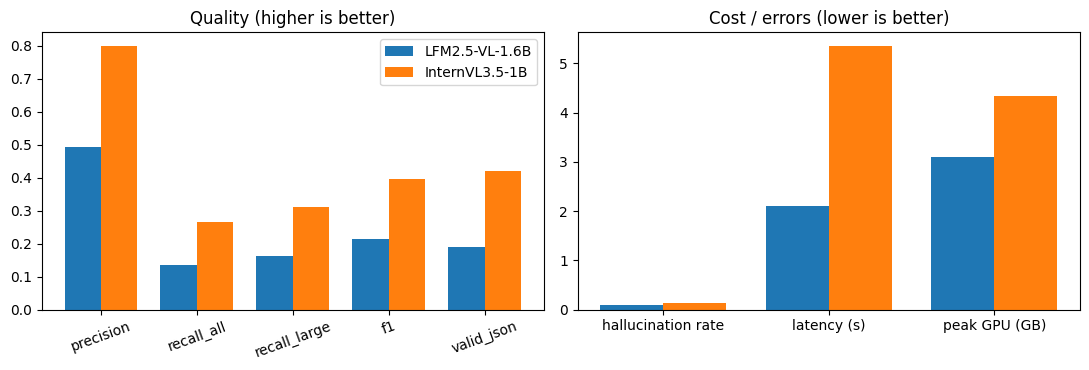

In [19]:
# NEW CELL — paste after the results table (Cell 11). Needs: METRICS, PER, names from earlier cells.
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# 1) Re-construct METRICS and PER if they are missing from the global state
globals_check = "METRICS" in globals() and "PER" in globals() and "names" in globals()

if not globals_check:
    # Fallback: attempt to reconstruct metrics using cached files on disk
    try:
        # Ensure we have CLASSES defined
        if "CLASSES" not in globals():
            if os.path.exists("classes.json"):
                CLASSES = json.load(open("classes.json"))
            else:
                from datasets import load_dataset_builder
                b = load_dataset_builder("detection-datasets/coco")
                cat = b.info.features["objects"]["category"]
                CLASSES = list(getattr(cat, "feature", cat).names)
        CLASS_SET = set(CLASSES)

        # Re-load samples and rebuild GT if missing
        if "samples" not in globals():
            from datasets import load_dataset
            ds = load_dataset("detection-datasets/coco", split="val", streaming=True)
            samples = list(ds.take(100))

        if "GT_ALL" not in globals() or "GT_LARGE" not in globals():
            GT_ALL, GT_LARGE = [], []
            for s in samples:
                W, H = s["image"].size
                names_list = [CLASSES[c] for c in s["objects"]["category"]]
                # Assume xyxy format
                fracs = [((b[2] - b[0]) * (b[3] - b[1])) / (W * H) for b in s["objects"]["bbox"]]
                GT_ALL.append(set(names_list))
                GT_LARGE.append({n for n, f in zip(names_list, fracs) if f >= 0.01})

        # Load cached results
        RESULTS = {}
        for name in ["LFM2.5-VL-1.6B", "InternVL3.5-1B"]:
            cache_path = f"/content/raw_{name}.json"
            if os.path.exists(cache_path):
                RESULTS[name] = json.load(open(cache_path))

        # Define parse and scoring helpers
        def parse_output(raw):
            try: obj = json.loads(raw.strip())
            except Exception: return None, "bad_json"
            if not isinstance(obj, list) or not all(isinstance(x, str) for x in obj):
                return None, "wrong_type"
            if any(x not in CLASS_SET for x in obj): return None, "out_of_vocab"
            return set(obj), None

        def score_model(name):
            R = RESULTS[name]; rows = []
            for i, raw in enumerate(R["raw"]):
                pred, reason = parse_output(raw)
                p = pred if pred is not None else set()
                gt, gtl = GT_ALL[i], GT_LARGE[i]
                rows.append(dict(
                    idx=i, valid=pred is not None, reason=reason, pred=p, gt=gt, gt_large=gtl, raw=raw,
                    tp=len(p & gt), n_pred=len(p), n_gt=len(gt),
                    tp_large=len(p & gtl), n_gt_large=len(gtl),
                    fp=sorted(p - gt), fn=sorted(gt - p),
                    halluc=len(p - gt) > 0, latency=R["latency"][i]))
            return pd.DataFrame(rows)

        PER = {n: score_model(n) for n in RESULTS}
        METRICS = {}
        for n in PER:
            df = PER[n]
            tp, n_pred, n_gt = df.tp.sum(), df.n_pred.sum(), df.n_gt.sum()
            tpl, n_gt_l = df.tp_large.sum(), df.n_gt_large.sum()
            P = tp / n_pred if n_pred else 0.0
            R = tp / n_gt if n_gt else 0.0
            RL = tpl / n_gt_l if n_gt_l else 0.0
            METRICS[n] = {
                "precision": P, "recall_all": R, "recall_large": RL, "f1": (2*P*R / (P+R) if (P+R) else 0.0),
                "hallucination": float(df.halluc.mean()),
                "valid_json": float(df.valid.mean()),
                "latency": float(df.latency.mean()),
                "peak_gb": RESULTS[n]["peak_gb"]}
        names = list(METRICS.keys())
    except Exception as e:
        raise RuntimeError("Could not automatically rebuild metrics. Please execute CELL 2 through CELL 11 first.") from e

a, b = names[0], names[1]

# 1) Winner per metric
higher_better = {"precision": True, "recall_all": True, "recall_large": True, "f1": True,
                 "valid_json": True, "hallucination": False, "latency": False, "peak_gb": False}
rows, wins = [], Counter()
for k, hb in higher_better.items():
    va, vb = METRICS[a][k], METRICS[b][k]
    if abs(va - vb) < 1e-9: w = "tie"
    else: w = a if (va > vb) == hb else b
    wins[w] += 1
    rows.append({"metric": k, a: round(va, 3), b: round(vb, 3), "better": w})
cmp_df = pd.DataFrame(rows).set_index("metric")
display(cmp_df)
print("Wins:", dict(wins))

# 2) Bootstrap
def micro_f1(df, idx):
    d = df.iloc[idx]
    tp, npred, ngt = d.tp.sum(), d.n_pred.sum(), d.n_gt.sum()
    P, R = tp / npred if npred else 0, tp / ngt if ngt else 0
    return 2 * P * R / (P + R) if (P + R) else 0

rng = np.random.default_rng(0)
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(PER[a]), len(PER[a]))
    diffs.append(micro_f1(PER[a], idx) - micro_f1(PER[b], idx))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nF1 difference ({a} - {b}): {METRICS[a]['f1'] - METRICS[b]['f1']:+.3f}   95% CI [{lo:+.3f}, {hi:+.3f}]")
print("-> CI includes 0: the F1 gap could be noise with only 100 images." if lo <= 0 <= hi
      else "-> CI excludes 0: the F1 gap is unlikely to be noise.")

# 3) Charts
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
q = ["precision", "recall_all", "recall_large", "f1", "valid_json"]
x = np.arange(len(q)); w = 0.38
ax[0].bar(x - w/2, [METRICS[a][k] for k in q], w, label=a)
ax[0].bar(x + w/2, [METRICS[b][k] for k in q], w, label=b)
ax[0].set_xticks(x); ax[0].set_xticklabels(q, rotation=20); ax[0].set_title("Quality (higher is better)"); ax[0].legend()
c = ["hallucination", "latency", "peak_gb"]; x = np.arange(len(c))
ax[1].bar(x - w/2, [METRICS[a][k] for k in c], w, label=a)
ax[1].bar(x + w/2, [METRICS[b][k] for k in c], w, label=b)
ax[1].set_xticks(x); ax[1].set_xticklabels(["hallucination rate", "latency (s)", "peak GPU (GB)"]); ax[1].set_title("Cost / errors (lower is better)")
plt.tight_layout(); plt.show()